# 08 · Autoencoders and Variational Autoencoders

An **autoencoder** learns to copy its input through a narrow bottleneck. The encoder compresses $x$ into a small code $z$; the decoder rebuilds $\hat x$ from $z$. Because $z$ is much smaller than $x$, the network must keep only what matters:
$$z = f_\theta(x),\qquad \hat x = g_\phi(z),\qquad L=\text{reconstruction error}(x,\hat x)$$

A plain autoencoder has a weakness: nothing forces the latent space to be *organized*. Codes of real data can land anywhere, with empty gaps between them, so decoding a random $z$ often gives garbage.

A **variational autoencoder (VAE)** fixes this by making the code a *distribution*. The encoder outputs a mean and log-variance, $q(z|x)=\mathcal N(\mu,\sigma^2)$, and training pushes every posterior toward a standard normal prior $p(z)=\mathcal N(0,I)$. The loss is the negative ELBO:
$$L = \underbrace{-\mathbb E_{q}[\log p(x|z)]}_{\text{reconstruction}} + \beta\,\underbrace{\mathrm{KL}\big(q(z|x)\,\|\,\mathcal N(0,I)\big)}_{\text{keeps the latent space regular}},\qquad \mathrm{KL}=-\tfrac12\sum_j\big(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\big)$$

**Reparameterization trick.** Sampling $z\sim\mathcal N(\mu,\sigma^2)$ is not differentiable. Write it as $z=\mu+\sigma\odot\varepsilon$ with $\varepsilon\sim\mathcal N(0,I)$ so the randomness is an *input* and gradients flow to $\mu,\sigma$.

**Backward pass** (with $\ell=\log\sigma^2$, $\sigma=e^{\ell/2}$, and $dz$ = gradient arriving from the decoder):
$$d\mu = dz + \beta\mu,\qquad d\ell = dz\odot\varepsilon\odot\tfrac12\sigma + \tfrac\beta2\big(e^{\ell}-1\big)$$

## The data
Images of a Gaussian blob. Its centre $(c_x,c_y)$ is the **only** thing that varies, so there are exactly two hidden factors and a 2-D latent space is enough. That lets us check what the latent space actually learned. No dataset download needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [2]:
SIZE = 12
yy, xx = np.mgrid[0:SIZE, 0:SIZE]


def render(cx, cy, sigma=1.5):
    """Gaussian blobs centred at (cx, cy); returns (n, SIZE, SIZE) with values in [0, 1]."""
    cx, cy = np.atleast_1d(cx), np.atleast_1d(cy)
    return np.exp(-((xx[None] - cx[:, None, None]) ** 2 + (yy[None] - cy[:, None, None]) ** 2) / (2 * sigma ** 2))


def make_dataset(n, seed):
    rng = np.random.RandomState(seed)
    centres = rng.uniform(3, 8, (n, 2))
    return render(centres[:, 0], centres[:, 1]).reshape(n, -1), centres


def show_grid(imgs, rows, cols, title=None, ax=None):
    """Tile (rows*cols, SIZE*SIZE) images into one mosaic."""
    mosaic = imgs.reshape(rows, cols, SIZE, SIZE).transpose(0, 2, 1, 3).reshape(rows * SIZE, cols * SIZE)
    ax = ax or plt.gca()
    ax.imshow(mosaic, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")

train (2000, 144), test (500, 144)  (each image is 12x12 = 144 pixels)


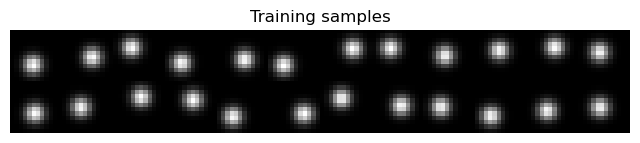

In [3]:
X_train, C_train = make_dataset(2000, seed=42)
X_test, C_test = make_dataset(500, seed=7)
print(f"train {X_train.shape}, test {X_test.shape}  (each image is {SIZE}x{SIZE} = {SIZE*SIZE} pixels)")

plt.figure(figsize=(8, 2.4))
show_grid(X_train[:24], 2, 12, "Training samples")
plt.show()

## Building blocks
`Dense` layers store their gradients in preallocated arrays (filled in place on `backward`), so one Adam optimizer can hold `(param, grad)` pairs. `MLP` stacks Dense layers with ReLU between them; the last layer is linear (the decoder's outputs are *logits*).

In [4]:
class Dense:
    def __init__(self, d_in, d_out):
        self.W = np.random.randn(d_in, d_out) * np.sqrt(2.0 / d_in)
        self.b = np.zeros(d_out)
        self.dW, self.db = np.zeros_like(self.W), np.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW[...] = self.x.T @ dout
        self.db[...] = dout.sum(axis=0)
        return dout @ self.W.T


class MLP:
    """Dense layers with ReLU in between; last layer linear."""

    def __init__(self, sizes):
        self.layers = [Dense(a, b) for a, b in zip(sizes[:-1], sizes[1:])]

    def forward(self, x):
        self.masks = []
        for i, layer in enumerate(self.layers):
            x = layer.forward(x)
            if i < len(self.layers) - 1:
                self.masks.append(x > 0)
                x = x * self.masks[-1]
        return x

    def backward(self, dout):
        for i in reversed(range(len(self.layers))):
            if i < len(self.layers) - 1:
                dout = dout * self.masks[i]
            dout = self.layers[i].backward(dout)
        return dout

    def parameters(self):
        return [(p, g) for l in self.layers for p, g in ((l.W, l.dW), (l.b, l.db))]


class Adam:
    def __init__(self, pairs, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.pairs, self.lr, self.b1, self.b2, self.eps, self.t = pairs, lr, b1, b2, eps, 0
        self.m = [np.zeros_like(p) for p, _ in pairs]
        self.v = [np.zeros_like(p) for p, _ in pairs]

    def step(self):
        self.t += 1
        for i, (p, g) in enumerate(self.pairs):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g ** 2
            p -= self.lr * (self.m[i] / (1 - self.b1 ** self.t)) / (np.sqrt(self.v[i] / (1 - self.b2 ** self.t)) + self.eps)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def bce_with_logits(logits, x):
    """Per-image binary cross-entropy summed over pixels, averaged over the batch (numerically stable)."""
    return (np.maximum(logits, 0) - logits * x + np.log1p(np.exp(-np.abs(logits)))).sum(axis=1).mean()

## Part 1 · Plain autoencoder
Encoder `144 → 128 → 2`, decoder `2 → 128 → 144`. The decoder emits logits; the reconstruction loss is binary cross-entropy summed over pixels. With sigmoid + BCE the gradient at the logits is simply $(\sigma(\text{logits})-x)/N$.

In [5]:
class Autoencoder:
    def __init__(self, d_in, d_hidden, d_latent):
        self.enc = MLP([d_in, d_hidden, d_latent])
        self.dec = MLP([d_latent, d_hidden, d_in])

    def forward(self, x):
        self.x = x
        self.z = self.enc.forward(x)
        self.logits = self.dec.forward(self.z)
        recon = bce_with_logits(self.logits, x)
        return recon, recon, 0.0           # (total, reconstruction, kl)

    def backward(self):
        N = len(self.x)
        self.enc.backward(self.dec.backward((sigmoid(self.logits) - self.x) / N))

    def encode(self, x):
        return self.enc.forward(x)

    def decode(self, z):
        return sigmoid(self.dec.forward(z))

    def reconstruct(self, x):
        return self.decode(self.encode(x))

    def parameters(self):
        return self.enc.parameters() + self.dec.parameters()

## Verify backward against finite differences
Before training, perturb random entries of every parameter and compare with the analytic gradient. The same helper is reused for the VAE below.

In [6]:
def grad_check(loss_fn, pairs, samples_per_param=3, eps=1e-5, seed=0):
    """Worst relative error between analytic grads and central finite differences."""
    rng = np.random.RandomState(seed)
    worst = 0.0
    for p, g in pairs:
        for _ in range(samples_per_param):
            idx = tuple(rng.randint(0, s) for s in p.shape)
            orig = p[idx]
            p[idx] = orig + eps; lp = loss_fn()
            p[idx] = orig - eps; lm = loss_fn()
            p[idx] = orig
            num = (lp - lm) / (2 * eps)
            worst = max(worst, abs(num - g[idx]) / (abs(num) + abs(g[idx]) + 1e-6))
    return worst


np.random.seed(0)
xb = X_train[:5]
ae_check = Autoencoder(SIZE * SIZE, 16, 2)
ae_check.forward(xb); ae_check.backward()
err = grad_check(lambda: ae_check.forward(xb)[0], ae_check.parameters())
print(f"autoencoder: worst relative error {err:.2e}")
assert err < 1e-5, "autoencoder backward disagrees with finite differences"

autoencoder: worst relative error 3.39e-07


In [7]:
def fit(model, X, epochs, batch=64, lr=1e-3, seed=0):
    opt = Adam(model.parameters(), lr=lr)
    rng = np.random.RandomState(seed)
    history = []
    for _ in range(epochs):
        perm = rng.permutation(len(X))
        tot = np.zeros(3)
        for i in range(0, len(X), batch):
            xb = X[perm[i:i + batch]]
            tot += np.array(model.forward(xb)) * len(xb)
            model.backward()
            opt.step()
        history.append(tot / len(X))
    return np.array(history)          # columns: total, reconstruction, kl


EPOCHS = 150
np.random.seed(1)
ae = Autoencoder(SIZE * SIZE, 128, 2)
ae_hist = fit(ae, X_train, EPOCHS)
print(f"final train loss {ae_hist[-1, 0]:.3f}")

final train loss 23.125


### Reconstructions and the learned latent space
Top row: test images. Bottom row: their reconstructions from just **2 numbers**. The scatter shows each test image's 2-D code, colored by the true blob position it never saw during training. If the code is meaningful it should vary smoothly with those colors.

per-pixel MSE: autoencoder 0.00051 | predict-the-mean baseline 0.02464  (48x better)


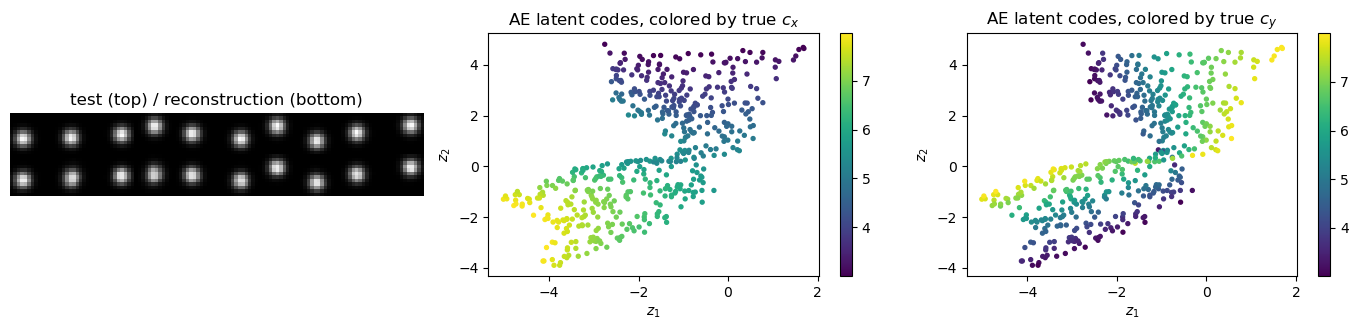

In [8]:
mean_baseline = np.mean((X_test - X_train.mean(axis=0)) ** 2)      # error of always predicting the average image
ae_mse = np.mean((ae.reconstruct(X_test) - X_test) ** 2)
print(f"per-pixel MSE: autoencoder {ae_mse:.5f} | predict-the-mean baseline {mean_baseline:.5f}  ({mean_baseline / ae_mse:.0f}x better)")
assert ae_mse < 0.1 * mean_baseline, "autoencoder should reconstruct far better than the mean image"

Z_ae = ae.encode(X_test)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
show_grid(np.vstack([X_test[:10], ae.reconstruct(X_test[:10])]), 2, 10, "test (top) / reconstruction (bottom)", axes[0])
for ax, k, name in [(axes[1], 0, "true $c_x$"), (axes[2], 1, "true $c_y$")]:
    sc = ax.scatter(Z_ae[:, 0], Z_ae[:, 1], c=C_test[:, k], cmap="viridis", s=8)
    ax.set(title=f"AE latent codes, colored by {name}", xlabel="$z_1$", ylabel="$z_2$"); plt.colorbar(sc, ax=ax)
plt.tight_layout(); plt.show()

## Part 2 · Variational autoencoder
Same sizes, but the encoder outputs $\mu$ and $\log\sigma^2$ (so `144 → 128 → 4`), a latent $z=\mu+\sigma\varepsilon$ is sampled, and the KL term is added. `forward` accepts a fixed $\varepsilon$ so the finite-difference check sees a deterministic function.

In [9]:
class VAE:
    def __init__(self, d_in, d_hidden, d_latent, beta=1.0):
        self.L, self.beta = d_latent, beta
        self.enc = MLP([d_in, d_hidden, 2 * d_latent])     # outputs [mu | logvar]
        self.dec = MLP([d_latent, d_hidden, d_in])

    def forward(self, x, eps=None):
        self.x = x
        h = self.enc.forward(x)
        self.mu, self.logvar = h[:, :self.L], h[:, self.L:]
        self.std = np.exp(0.5 * self.logvar)
        self.eps = np.random.randn(*self.mu.shape) if eps is None else eps
        self.z = self.mu + self.std * self.eps                 # reparameterization trick
        self.logits = self.dec.forward(self.z)
        recon = bce_with_logits(self.logits, x)
        kl = (-0.5 * (1 + self.logvar - self.mu ** 2 - np.exp(self.logvar)).sum(axis=1)).mean()
        return recon + self.beta * kl, recon, kl

    def backward(self):
        N = len(self.x)
        dz = self.dec.backward((sigmoid(self.logits) - self.x) / N)
        dmu = dz + self.beta * self.mu / N
        dlogvar = dz * self.eps * 0.5 * self.std + self.beta * 0.5 * (np.exp(self.logvar) - 1) / N
        self.enc.backward(np.concatenate([dmu, dlogvar], axis=1))

    def encode(self, x):                                       # posterior mean = the "code" of x
        return self.enc.forward(x)[:, :self.L]

    def decode(self, z):
        return sigmoid(self.dec.forward(z))

    def reconstruct(self, x):
        return self.decode(self.encode(x))

    def parameters(self):
        return self.enc.parameters() + self.dec.parameters()

In [10]:
np.random.seed(0)
vae_check = VAE(SIZE * SIZE, 16, 2)
eps_fixed = np.random.randn(5, 2)
vae_check.forward(xb, eps=eps_fixed); vae_check.backward()
err = grad_check(lambda: vae_check.forward(xb, eps=eps_fixed)[0], vae_check.parameters())
print(f"VAE: worst relative error {err:.2e}")
assert err < 1e-5, "VAE backward (reparameterization + KL) disagrees with finite differences"

VAE: worst relative error 8.61e-07


In [11]:
np.random.seed(1)
vae = VAE(SIZE * SIZE, 128, 2, beta=1.0)
vae_hist = fit(vae, X_train, EPOCHS)
print(f"final train: total {vae_hist[-1, 0]:.3f} = reconstruction {vae_hist[-1, 1]:.3f} + KL {vae_hist[-1, 2]:.3f}")

final train: total 26.919 = reconstruction 24.130 + KL 2.789


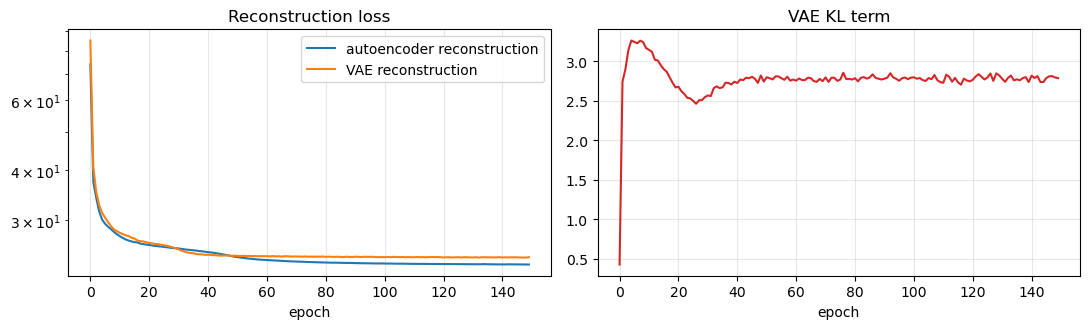

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(ae_hist[:, 1], label="autoencoder reconstruction"); axes[0].plot(vae_hist[:, 1], label="VAE reconstruction")
axes[0].set(title="Reconstruction loss", xlabel="epoch", yscale="log"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(vae_hist[:, 2], color="C3"); axes[1].set(title="VAE KL term", xlabel="epoch"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### VAE latent space
The posterior means should again track the blob position — but now they are pulled into a compact, roughly standard-normal cloud, with no big empty gaps.

VAE latent: mean [-0.    0.04], std [0.95 0.99]   (prior is mean 0, std 1)
AE  latent: mean [-1.81  0.58], std [1.38 2.27]   (unconstrained)


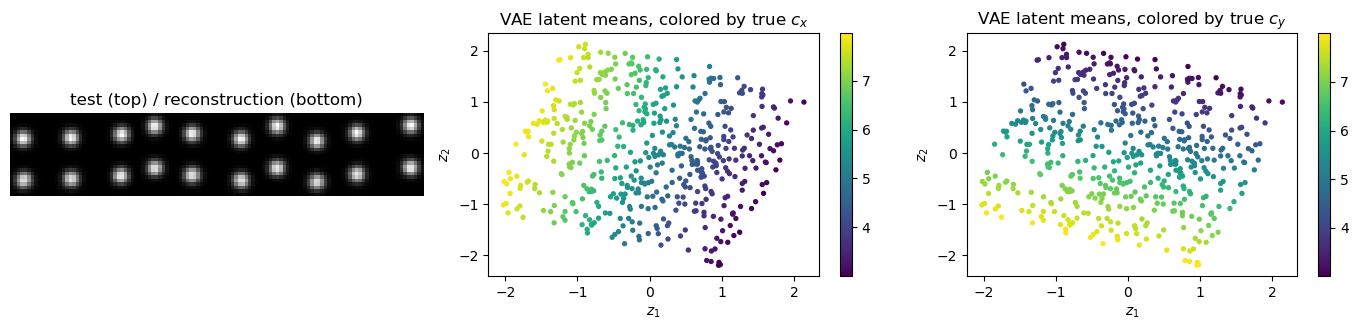

In [13]:
Z_vae = vae.encode(X_test)
print(f"VAE latent: mean {Z_vae.mean(axis=0).round(2)}, std {Z_vae.std(axis=0).round(2)}   (prior is mean 0, std 1)")
print(f"AE  latent: mean {Z_ae.mean(axis=0).round(2)}, std {Z_ae.std(axis=0).round(2)}   (unconstrained)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
show_grid(np.vstack([X_test[:10], vae.reconstruct(X_test[:10])]), 2, 10, "test (top) / reconstruction (bottom)", axes[0])
for ax, k, name in [(axes[1], 0, "true $c_x$"), (axes[2], 1, "true $c_y$")]:
    sc = ax.scatter(Z_vae[:, 0], Z_vae[:, 1], c=C_test[:, k], cmap="viridis", s=8)
    ax.set(title=f"VAE latent means, colored by {name}", xlabel="$z_1$", ylabel="$z_2$"); plt.colorbar(sc, ax=ax)
plt.tight_layout(); plt.show()

## Generating new images: decode samples from the prior
Draw $z\sim\mathcal N(0,I)$ and decode. This is the VAE's whole purpose. We try the same on the plain autoencoder to see why it can't generate: its latent space has no prior to sample from.

To score "does this look like a real blob?", fit a blob to each decoded image (centre of mass, best amplitude) and measure what fraction of the image is left unexplained.

In [14]:
def unexplained(imgs):
    """Fraction of each image's energy NOT explained by a single fitted Gaussian blob (0 = perfect blob)."""
    m = imgs.reshape(len(imgs), SIZE, SIZE)
    mass = m.sum(axis=(1, 2)) + 1e-9
    ref = render((m * xx).sum(axis=(1, 2)) / mass, (m * yy).sum(axis=(1, 2)) / mass).reshape(len(imgs), -1)
    amp = (imgs * ref).sum(axis=1) / ((ref * ref).sum(axis=1) + 1e-9)
    return ((imgs - amp[:, None] * ref) ** 2).sum(axis=1) / ((imgs ** 2).sum(axis=1) + 1e-9)


rng = np.random.RandomState(0)
Z_prior = rng.randn(400, 2)
samples = {"autoencoder": ae.decode(Z_prior), "VAE": vae.decode(Z_prior)}
clean = {}
for name, imgs in samples.items():
    ok = (unexplained(imgs) < 0.1) & (imgs.max(axis=1) > 0.5)
    clean[name] = ok.mean()
    print(f"{name:<12} {clean[name]:.0%} of 400 prior samples decode to a clean blob")
assert clean["VAE"] > 0.9, "VAE prior samples should decode to clean blobs"
assert clean["VAE"] > clean["autoencoder"], "VAE should generate better than the plain autoencoder"

autoencoder  74% of 400 prior samples decode to a clean blob
VAE          100% of 400 prior samples decode to a clean blob


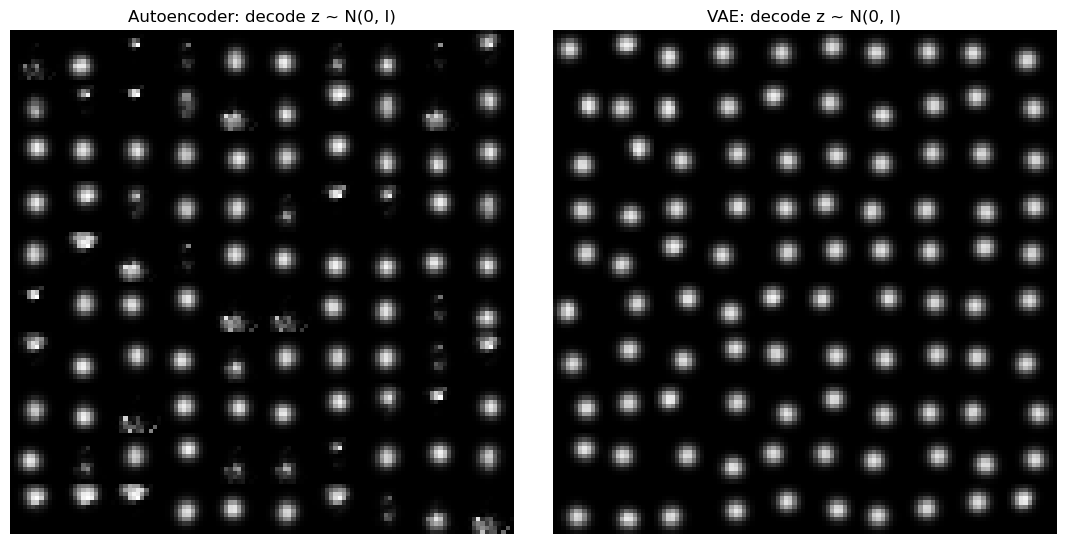

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
show_grid(samples["autoencoder"][:100], 10, 10, "Autoencoder: decode z ~ N(0, I)", axes[0])
show_grid(samples["VAE"][:100], 10, 10, "VAE: decode z ~ N(0, I)", axes[1])
plt.tight_layout(); plt.show()

### Walking the latent grid
Decode a regular 12×12 grid of latent points over $[-2.5, 2.5]^2$. In a good VAE, moving through latent space moves the blob smoothly across the image — the two latent axes have become the two hidden factors (possibly rotated or mixed).

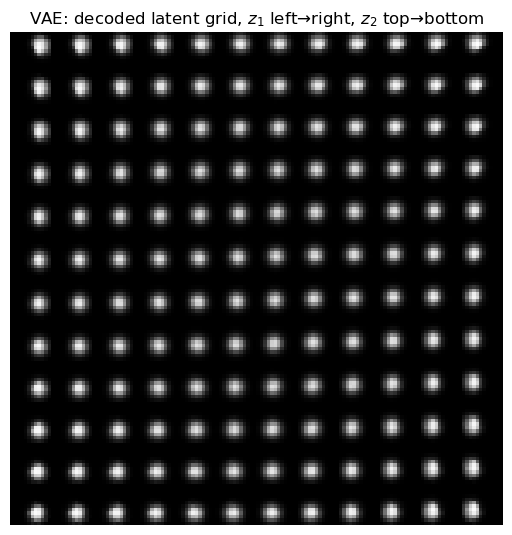

In [16]:
g = np.linspace(-2.5, 2.5, 12)
grid_z = np.array([[a, b] for b in g[::-1] for a in g])
plt.figure(figsize=(6.4, 6.4))
show_grid(vae.decode(grid_z), 12, 12, "VAE: decoded latent grid, $z_1$ left→right, $z_2$ top→bottom")
plt.show()

## Takeaways
- **Autoencoder**: compresses well (reconstruction far better than the mean image), but its latent space is unconstrained, so it can't be sampled.
- **VAE**: the KL term trades a little reconstruction quality for a regular, sampleable latent space; random draws from $\mathcal N(0,I)$ decode to valid images.
- Try `beta` in `VAE(..., beta=...)`: larger $\beta$ → smoother latent space but blurrier reconstructions (and eventually *posterior collapse*, where the decoder ignores $z$); smaller $\beta$ → sharper reconstructions, less regular latent space.

**Next**: word embeddings (`09`), GANs (`10`), residual networks (`11`), or an autograd engine (`12`).